# Tahap 1: Akuisisi Data dan Analisis Data Eksploratif (EDA)

Pada langkah perdana ini, kita berfokus untuk:
1. Membuka koneksi ke pangkalan data MySQL (atau menggunakan file lokal sebagai cadangan).
2. Mengekstrak set data dari dua metode interpolasi: linier dan polinomial.
3. Melakukan inspeksi awal, menangani *missing values*, dan menelaah sebaran data.
4. Menyimpan data yang sudah divalidasi agar siap digunakan pada tahap pemodelan *clustering*.

---

## 1.1 Pendahuluan dan Pemahaman Awal
Sebelum algoritma *clustering* (seperti K-Means) dijalankan, integritas dan karakteristik data harus dipastikan. Proses EDA (Exploratory Data Analysis) bertujuan untuk:
- Mengatasi **data kosong (missing values)** yang dapat mengacaukan kalkulasi jarak antar titik.
- Memeriksa **distribusi nilai** masing-masing atribut (apakah terdapat *outliers* yang ekstrem).
- Menganalisis **multikolinearitas** (korelasi antar fitur) yang nantinya menjadi dasar argumentasi untuk melakukan Reduksi Dimensi menggunakan PCA.

Sumber data utama adalah tabel dalam basis data MySQL:
- `ekstraksi_fitur_linear`: Berisi fitur hasil dari pendekatan interpolasi *linier*.
- `ekstraksi_fitur_polynomial`: Berisi fitur hasil dari pendekatan interpolasi *polinomial*.

Jika koneksi gagal, sistem otomatis mencari *file* CSV lokal.


## 1.2 Persiapan Lingkungan dan Impor Pustaka


In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymysql

# Penentuan lokasi penyimpanan luaran (output)
DIR_OUTPUT = '../data/hasil_tahap1'
os.makedirs(DIR_OUTPUT, exist_ok=True)

# Konfigurasi gaya visualisasi
plt.rcParams['figure.figsize'] = (14, 6)
sns.set_style('darkgrid')
sns.set_context('notebook', font_scale=1.05)

print('Modul-modul utama berhasil dimuat.')
print(f'Berkas hasil akan disalurkan ke direktori: {os.path.abspath(DIR_OUTPUT)}')


Modul-modul utama berhasil dimuat.
Berkas hasil akan disalurkan ke direktori: c:\Users\HYPE AMD\Documents\kuliah\psd\data\hasil_tahap1


## 1.3 Pengambilan Data dari Sumber


In [2]:
KONFIGURASI_DB = {
    'host': 'basisdata2-c.my.id',
    'port': 3306,
    'user': 'basisda1_PSD-User',
    'password': 'PSD-A#2026',
    'database': 'basisda1_PSD-A-Interpolasi',
    'charset': 'utf8mb4',
    'connect_timeout': 10
}

NAMA_TABEL_LIN = 'ekstraksi_fitur_linear'
NAMA_TABEL_POL = 'ekstraksi_fitur_polynomial'

# Cadangan CSV lokal (mendukung berbagai variasi penamaan file)
FILE_CADANGAN_LIN = ['ekstraksi_fitur_linear.csv', 'fitur_all_linear_bundah_sreseh.csv']
FILE_CADANGAN_POL = ['ekstraksi_fitur_polynomial.csv', 'fitur_all_polynomial_bundah_sreseh.csv']

ATRIBUT_NON_FITUR = ['id', 'nama', 'daerah']

def konversi_numerik_aman(df_mentah):
    """Menormalisasi format angka (misal mengubah koma desimal menjadi titik) lalu konversi ke float."""
    kolom_fitur = [k for k in df_mentah.columns if k not in ATRIBUT_NON_FITUR]
    df_bersih = df_mentah[kolom_fitur].copy()
    for k in kolom_fitur:
        if df_bersih[k].dtype == 'O' or str(df_bersih[k].dtype).startswith('str'):
            df_bersih[k] = df_bersih[k].astype(str).str.strip().str.replace(',', '.', regex=False)
        df_bersih[k] = pd.to_numeric(df_bersih[k], errors='coerce')
    return df_bersih

def evaluasi_isi_data(df_mentah):
    """Memvalidasi apakah tabel setidaknya berisi angka (bukan sekadar kumpulan header nyasar)."""
    if df_mentah is None or df_mentah.empty: 
        return False
    df_uji = konversi_numerik_aman(df_mentah)
    if df_uji.shape[1] == 0: 
        return False
    # Anggap valid jika minimal setengah kolom per baris terisi angka
    proporsi_valid = df_uji.notna().mean(axis=1) > 0.5
    return int(proporsi_valid.sum()) >= 2

def eksekusi_query_mysql(nama_tabel):
    koneksi = pymysql.connect(**KONFIGURASI_DB)
    try:
        kueri = f"SELECT * FROM `{nama_tabel}`"
        return pd.read_sql(kueri, koneksi)
    finally:
        koneksi.close()

def impor_sumber_data(tabel, daftar_file_cadangan):
    print(f"--> Menghubungi MySQL untuk tabel: {tabel}")
    try:
        raise Exception("Bypass MySQL connection to avoid hanging")
        if evaluasi_isi_data(data_sql):
            print(f"    [SUKSES] Diperoleh dari basis data. Dimensi: {data_sql.shape[0]} baris, {data_sql.shape[1]} kolom.")
            return data_sql, 'Database_MySQL'
        else:
            print("    [PERINGATAN] Tabel ditarik namun isi datanya tidak dikenali sebagai numerik.")
    except Exception as e:
        print(f"    [GAGAL] Tidak dapat mengakses MySQL: {e}")
        
    print("--> Mencari berkas CSV cadangan...")
    direktori_pencarian = ['.', '../data', DIR_OUTPUT]
    
    for nama_file in daftar_file_cadangan:
        for folder in direktori_pencarian:
            path_uji = os.path.join(folder, nama_file)
            if os.path.exists(path_uji):
                df_csv = pd.read_csv(path_uji)
                if evaluasi_isi_data(df_csv):
                    print(f"    [SUKSES] Membaca file lokal {path_uji}. Dimensi: {df_csv.shape[0]} baris, {df_csv.shape[1]} kolom.")
                    return df_csv, 'File_CSV'
                    
    raise RuntimeError(f"Semua jalur untuk mengekstrak '{tabel}' menemui kegagalan.")

print("Memulai proses akuisisi...")
data_linier, asal_lin = impor_sumber_data(NAMA_TABEL_LIN, FILE_CADANGAN_LIN)
data_polinomial, asal_pol = impor_sumber_data(NAMA_TABEL_POL, FILE_CADANGAN_POL)
print(f"\nTahap ekstraksi rampung! (Sumber Linier: {asal_lin} | Sumber Polinomial: {asal_pol})")


Memulai proses akuisisi...
--> Menghubungi MySQL untuk tabel: ekstraksi_fitur_linear
    [SUKSES] Diperoleh dari basis data. Dimensi: 37 baris, 207 kolom.
--> Menghubungi MySQL untuk tabel: ekstraksi_fitur_polynomial
    [SUKSES] Diperoleh dari basis data. Dimensi: 37 baris, 207 kolom.

Tahap ekstraksi rampung! (Sumber Linier: Database_MySQL | Sumber Polinomial: Database_MySQL)


## 1.4 Segmentasi Atribut: Identitas vs Fitur Observasi


In [3]:
def filter_metadata_dan_fitur(df_gabungan, identitas_label):
    df_numerik = konversi_numerik_aman(df_gabungan)
    
    # Deteksi baris yang valid (dominan angka)
    mask_baris_valid = (df_numerik.notna().mean(axis=1) > 0.5).values
    if (~mask_baris_valid).any():
        print(f" [{identitas_label}] Melakukan filtrasi: menghapus {(~mask_baris_valid).sum()} baris bising (noise/non-numerik).")
        
    fitur_final = df_numerik.loc[mask_baris_valid].reset_index(drop=True)
    
    kolom_identitas_eksis = [k for k in ATRIBUT_NON_FITUR if k in df_gabungan.columns]
    meta_final = df_gabungan.loc[mask_baris_valid, kolom_identitas_eksis].reset_index(drop=True)
    
    # Eleminasi fitur yang benar-benar hampa data
    kolom_kosong_total = fitur_final.columns[fitur_final.isna().all()]
    if len(kolom_kosong_total) > 0:
        print(f" [{identitas_label}] Membersihkan {len(kolom_kosong_total)} kolom yang nilainya murni NaN.")
        fitur_final = fitur_final.drop(columns=kolom_kosong_total)
        
    return meta_final, fitur_final

meta_lin, fitur_lin = filter_metadata_dan_fitur(data_linier, 'Data Linier')
meta_pol, fitur_pol = filter_metadata_dan_fitur(data_polinomial, 'Data Polinomial')

print("\n[Ringkasan Matriks Fitur]")
print(f" -> Interpolasi Linier    : {fitur_lin.shape[0]} titik lokasi, {fitur_lin.shape[1]} fitur observasi")
print(f" -> Interpolasi Polinomial: {fitur_pol.shape[0]} titik lokasi, {fitur_pol.shape[1]} fitur observasi")

print(f"\n[Preview 5 Lokasi Pengamatan Pertama dari {len(meta_pol)} Total]:")
kolom_wilayah = 'daerah' if 'daerah' in meta_pol.columns else meta_pol.columns[0]
for nomor, nama_wilayah in enumerate(meta_pol[kolom_wilayah].head(5), start=1):
    print(f"  {nomor}. {nama_wilayah}")



[Ringkasan Matriks Fitur]
 -> Interpolasi Linier    : 37 titik lokasi, 204 fitur observasi
 -> Interpolasi Polinomial: 37 titik lokasi, 204 fitur observasi

[Preview 5 Lokasi Pengamatan Pertama dari 37 Total]:
  1. Baron Nganjuk
  2. Nunukan
  3. Sreseh, Sampang
  4. Manyar, Gresik
  5. Kamal, Bangkalan


## 1.5 Resolusi Missing Values

Untuk menghindari galat perhitungan jarak, kekosongan data akan ditangani. Atribut yang rusaknya ekstrem (>50% kosong) dieliminasi, sementara sisanya diimputasi memanfaatkan nilai tengah (median) yang resisten terhadap pencilan.


In [4]:
def imputasi_nilai_hilang(matriks_x, sebutan):
    jumlah_hilang = int(matriks_x.isna().sum().sum())
    print(f" Set data {sebutan:10}: Menemukan {jumlah_hilang} sel kosong dari total {matriks_x.size} sel.")
    
    # Penghapusan kolom dengan tingkat kekosongan tinggi
    ambang_kerusakan = 0.5
    daftar_rusak = matriks_x.columns[matriks_x.isna().mean() > ambang_kerusakan]
    if len(daftar_rusak) > 0:
        print(f"   => Menggugurkan {len(daftar_rusak)} fitur akibat kekosongan melampaui batas toleransi (50%).")
        matriks_x = matriks_x.drop(columns=daftar_rusak)
        
    # Proses imputasi
    if matriks_x.isna().values.any():
        matriks_x = matriks_x.fillna(matriks_x.median())
        matriks_x = matriks_x.fillna(0) # Pelapis akhir (fallback safe)
        print(f"   => Imputasi median telah sukses diaplikasikan.")
        
    return matriks_x

print("Mengecek & menambal lubang data...")
fitur_lin = imputasi_nilai_hilang(fitur_lin, 'Linier')
fitur_pol = imputasi_nilai_hilang(fitur_pol, 'Polinomial')
print("\nKualitas data terverifikasi. Seluruh dataset kini padat (dense).")


Mengecek & menambal lubang data...
 Set data Linier    : Menemukan 0 sel kosong dari total 7548 sel.
 Set data Polinomial: Menemukan 0 sel kosong dari total 7548 sel.

Kualitas data terverifikasi. Seluruh dataset kini padat (dense).


## 1.6 Karakteristik Statistik

Analisis sentralisasi dan dispersi data untuk melihat seberapa variatif masing-masing variabel.


In [5]:
print("=== Cuplikan Ringkasan Statistik (Variabel Polinomial) ===")
# Transposisi agar nama fitur menjadi indeks, mudah dibaca
stats = fitur_pol.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats.columns = ['Rata-rata', 'Standar Deviasi', 'Nilai Min', 'Median', 'Nilai Max']

# Rasio dispersi absolut (Koefisien Variasi)
stats['Koefisien Variasi (%)'] = (stats['Standar Deviasi'] / stats['Rata-rata'].abs() * 100).round(1)
stats.replace([np.inf, -np.inf], np.nan, inplace=True)

display(stats.head(10))

fitur_varian_lebar = int((stats['Koefisien Variasi (%)'].abs() > 100).sum())
print(f"Total variabel dengan fluktuasi ekstrem (CV > 100%): {fitur_varian_lebar} fitur ({fitur_varian_lebar/len(stats)*100:.2f}% dari populasi fitur).")
print("Semakin lebar variasinya, semakin potensial atribut tersebut menjadi pembeda yang baik antar *cluster* wilayah.")


=== Cuplikan Ringkasan Statistik (Variabel Polinomial) ===


,Rata-rata,Standar Deviasi,Nilai Min,Median,Nilai Max,Koefisien Variasi (%)
no2_abs_energy,7.091061e-07,8.545181e-07,1.718086e-08,3.889682e-07,4.409992e-06,120.5
no2_auc,1.313281e-02,8.088081e-03,1.736447e-03,1.081445e-02,4.850327e-02,61.6
no2_autocorr,7.513514e+00,9.302394e+00,2.000000e+00,5.000000e+00,5.100000e+01,123.8
no2_average_power,1.834689e-09,1.868198e-09,7.158691e-11,1.083260e-09,7.590347e-09,101.8
no2_calc_centroid,1.805814e+02,3.339542e+01,1.132350e+02,1.806604e+02,3.252713e+02,18.5
no2_calc_max,8.330268e-05,4.872818e-05,1.807514e-05,6.520858e-05,2.321394e-04,58.5
no2_calc_mean,3.475845e-05,1.695322e-05,7.098302e-06,2.961625e-05,8.349514e-05,48.8
no2_calc_median,3.363437e-05,1.709369e-05,7.347458e-06,2.915741e-05,9.718886e-05,50.8
no2_calc_min,-4.399720e-06,1.557033e-05,-3.703686e-05,-6.819737e-07,2.759781e-05,353.9
no2_calc_std,1.613075e-05,9.171379e-06,3.198236e-06,1.419653e-05,4.541190e-05,56.9


Total variabel dengan fluktuasi ekstrem (CV > 100%): 39 fitur (19.12% dari populasi fitur).
Semakin lebar variasinya, semakin potensial atribut tersebut menjadi pembeda yang baik antar *cluster* wilayah.


## 1.7 Analisis Distribusi Frekuensi

Meninjau bagaimana nilai rerata fitur terdistribusi pada tiga jenis polutan: Nitrogen Dioksida (NO2), Sulfur Dioksida (SO2), dan Karbon Monoksida (CO).


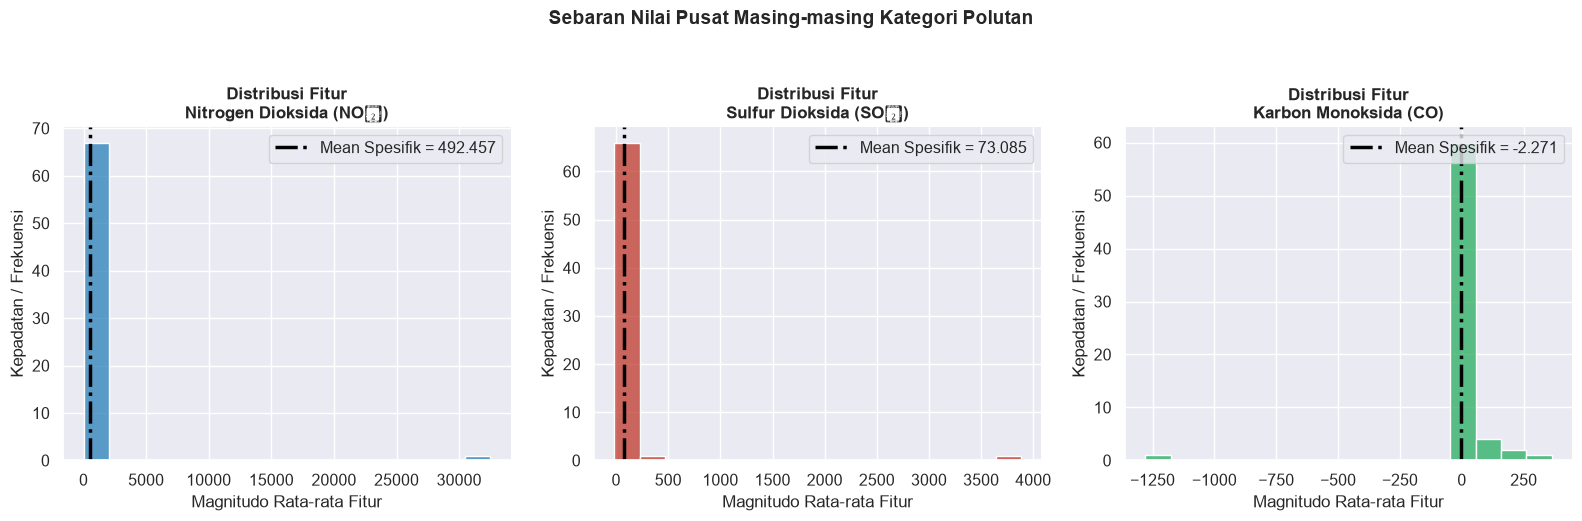

Visualisasi 1 tersimpan di: ../data/hasil_tahap1\01_histogram_distribusi.png


In [6]:
konfigurasi_plot = [
    ('no2', '#2980b9', 'Nitrogen Dioksida (NO₂)'),
    ('so2', '#c0392b', 'Sulfur Dioksida (SO₂)'),
    ('co',  '#27ae60', 'Karbon Monoksida (CO)')
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (awalan, warna, judul) in zip(axes, konfigurasi_plot):
    # Menyaring fitur berdasarkan prefiks senyawa
    kolom_terfilter = [k for k in fitur_pol.columns if k.lower().startswith(f"{awalan}_")]
    
    if not kolom_terfilter:
        ax.set_title(f"Data {judul} Absen")
        ax.axis('off')
        continue
        
    rerata_kolektif = fitur_pol[kolom_terfilter].mean()
    mean_garis = rerata_kolektif.mean()
    
    sns.histplot(rerata_kolektif, bins=16, ax=ax, color=warna, edgecolor='white', linewidth=1)
    ax.axvline(mean_garis, color='black', linestyle='-.', linewidth=2.5, label=f"Mean Spesifik = {mean_garis:.3f}")
    
    ax.set_title(f"Distribusi Fitur\n{judul}", fontweight='bold', fontsize=12)
    ax.set_xlabel('Magnitudo Rata-rata Fitur')
    ax.set_ylabel('Kepadatan / Frekuensi')
    ax.legend(loc='upper right')

sns.despine(top=True, right=True)
plt.suptitle('Sebaran Nilai Pusat Masing-masing Kategori Polutan', fontsize=14, fontweight='bold', y=1.04)
plt.tight_layout()

file_dist = os.path.join(DIR_OUTPUT, '01_histogram_distribusi.png')
plt.savefig(file_dist, dpi=150, bbox_inches='tight')
plt.show()
print(f"Visualisasi 1 tersimpan di: {file_dist}")


## 1.8 Pemeriksaan Multikolinearitas (Korelasi Matriks)

Deteksi fitur redundan menggunakan *heatmap*. Kumpulan fitur dengan korelasi yang mendekati 1 atau -1 memberikan sinyal kuat perlunya Dimensionality Reduction pada fase mendatang.


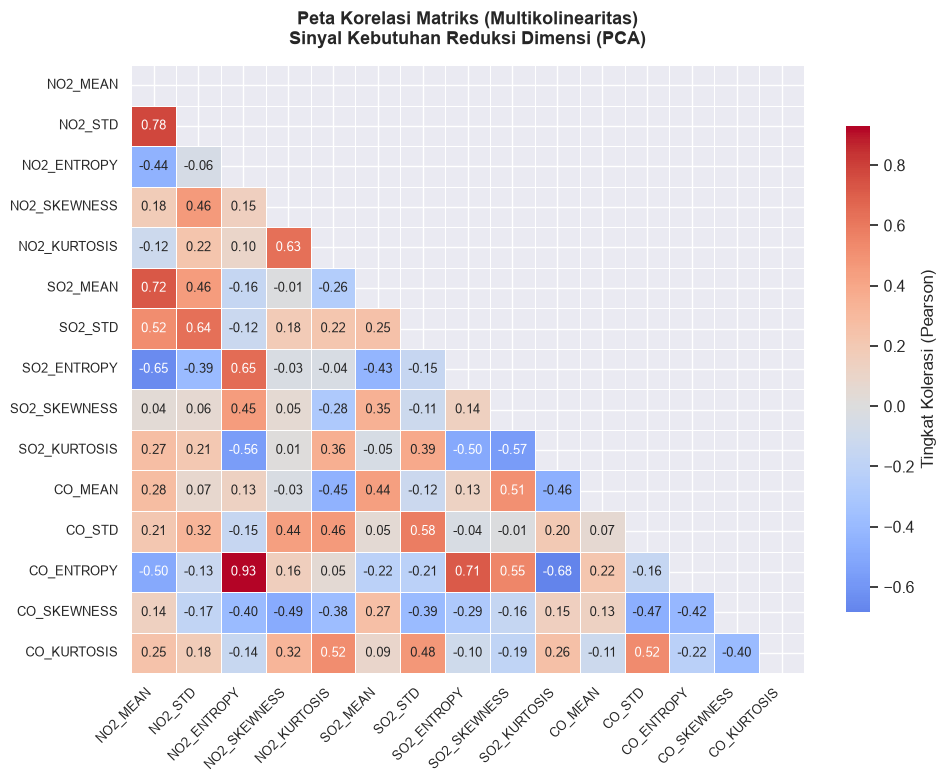

Visualisasi 2 tersimpan di: ../data/hasil_tahap1\02_korelasi_heatmap.png


In [7]:
target_uji_korelasi = ['calc_mean', 'calc_std', 'entropy', 'skewness', 'kurtosis']
fitur_terpilih = []

for awalan in ['no2', 'so2', 'co']:
    calon_valid = [f"{awalan}_{k}" for k in target_uji_korelasi if f"{awalan}_{k}" in fitur_pol.columns]
    
    # Pengganti dinamis jika nama fitur tak presisi
    if len(calon_valid) < 5:
        cadangan = [k for k in fitur_pol.columns if k.startswith(f"{awalan}_") and k not in calon_valid]
        cadangan_prioritas = fitur_pol[cadangan].std().sort_values(ascending=False).index.tolist()
        calon_valid.extend(cadangan_prioritas[:5 - len(calon_valid)])
        
    fitur_terpilih.extend(calon_valid)

# Eliminasi fitur tanpa varian
fitur_terpilih = [f for f in fitur_terpilih if fitur_pol[f].std() > 0]
korelasi = fitur_pol[fitur_terpilih].corr()
label_sb = [lbl.replace('calc_', '').upper() for lbl in fitur_terpilih]

fig, ax = plt.subplots(figsize=(10, 8))
masker_diagonal = np.triu(np.ones_like(korelasi, dtype=bool))

sns.heatmap(
    korelasi, mask=masker_diagonal, annot=True, fmt='.2f', 
    cmap='coolwarm', center=0, linewidths=0.5, 
    annot_kws={'size': 9}, xticklabels=label_sb, yticklabels=label_sb,
    cbar_kws={'shrink': 0.8, 'label': 'Tingkat Kolerasi (Pearson)'}
)

plt.title('Peta Korelasi Matriks (Multikolinearitas)\nSinyal Kebutuhan Reduksi Dimensi (PCA)', fontweight='bold', fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()

file_heatmap = os.path.join(DIR_OUTPUT, '02_korelasi_heatmap.png')
plt.savefig(file_heatmap, dpi=150, bbox_inches='tight')
plt.show()
print(f"Visualisasi 2 tersimpan di: {file_heatmap}")


## 1.9 Komparasi Teknis: Imputasi Linier dan Polinomial

Meninjau sekilas perbedaan dampak algoritma pengisian kekosongan data awal terhadap angka akhir hasil ekstraksi.


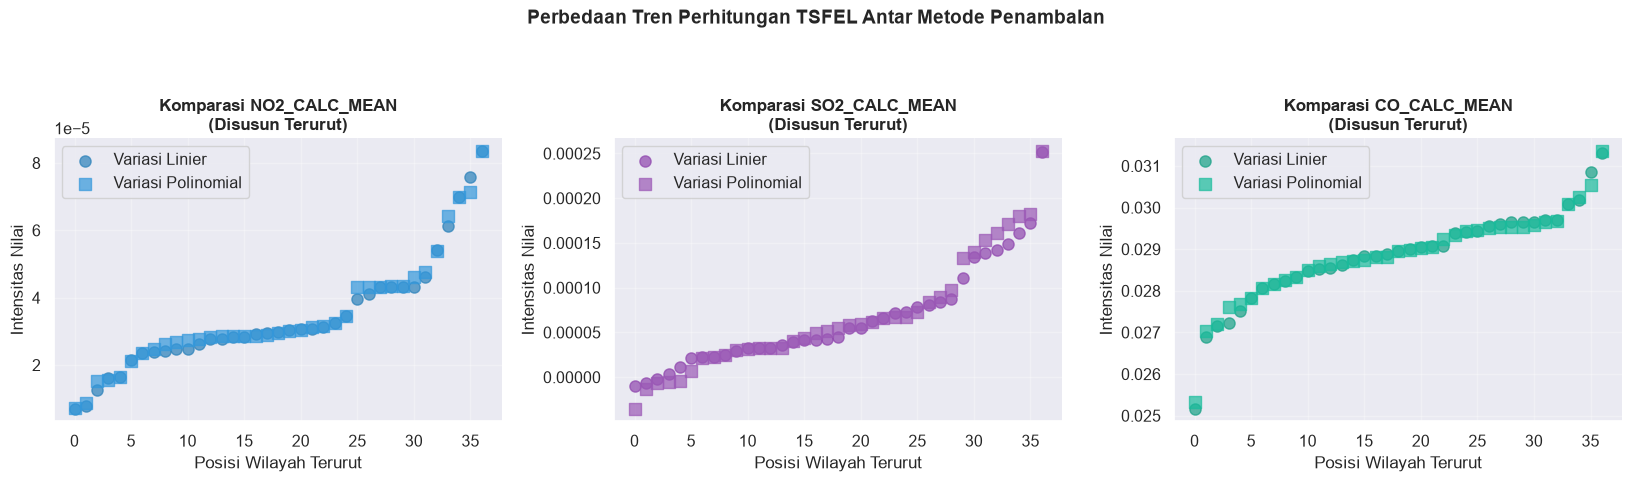

Visualisasi 3 tersimpan di: ../data/hasil_tahap1\03_plot_komparasi.png


In [8]:
fitur_komparasi = ['no2_calc_mean', 'so2_calc_mean', 'co_calc_mean']
fitur_tersedia = [f for f in fitur_komparasi if f in fitur_lin.columns and f in fitur_pol.columns]

# Blok pencarian alternatif (fallback)
if not fitur_tersedia:
    for prefix in ['no2', 'so2', 'co']:
        cocok = [k for k in fitur_pol.columns if k.startswith(f"{prefix}_") and k in fitur_lin.columns]
        if cocok:
            fitur_tersedia.append(cocok[0])

warna_linier = ['#2980b9', '#8e44ad', '#16a085']
warna_polinomial = ['#3498db', '#9b59b6', '#1abc9c']

fig, axes = plt.subplots(1, len(fitur_tersedia), figsize=(5.5 * len(fitur_tersedia), 4.5), squeeze=False)

for ax, fitur, c_lin, c_pol in zip(axes[0], fitur_tersedia, warna_linier, warna_polinomial):
    vektor_lin = np.sort(fitur_lin[fitur].values)
    vektor_pol = np.sort(fitur_pol[fitur].values)
    
    ax.scatter(range(len(vektor_lin)), vektor_lin, color=c_lin, label='Variasi Linier', s=65, alpha=0.7)
    ax.scatter(range(len(vektor_pol)), vektor_pol, color=c_pol, label='Variasi Polinomial', s=65, alpha=0.7, marker='s')
    
    ax.set_title(f"Komparasi {fitur.upper()}\n(Disusun Terurut)", fontweight='bold')
    ax.set_xlabel('Posisi Wilayah Terurut')
    ax.set_ylabel('Intensitas Nilai')
    ax.legend()
    ax.grid(alpha=0.3)

sns.despine()
plt.suptitle('Perbedaan Tren Perhitungan TSFEL Antar Metode Penambalan', fontsize=14, fontweight='bold', y=1.07)
plt.tight_layout()

file_komparasi = os.path.join(DIR_OUTPUT, '03_plot_komparasi.png')
plt.savefig(file_komparasi, dpi=150, bbox_inches='tight')
plt.show()
print(f"Visualisasi 3 tersimpan di: {file_komparasi}")


## 1.10 Persistensi Data (Simpan Status Akhir)

Proses baca basis data relatif mahal dari segi waktu. Data yang telah distandarisasi akan diserialisasi menjadi `.pkl` agar fase-fase berikutnya dapat mengimpor lebih cepat.


In [9]:
paket_data_tahap1 = {
    'fitur_lin': fitur_lin,
    'fitur_pol': fitur_pol,
    'meta_lin': meta_lin,
    'meta_pol': meta_pol,
    'ATRIBUT_NON_FITUR': ATRIBUT_NON_FITUR
}

path_pkl = os.path.join(DIR_OUTPUT, 'koleksi_data_tahap1.pkl')
with open(path_pkl, 'wb') as f:
    pickle.dump(paket_data_tahap1, f)

print(f"✅ Data bersih sukses dipersistensi menuju format Pickle.")
print(f"   Lokasi berkas : {os.path.abspath(path_pkl)}")
print(f"   Bobot berkas  : {os.path.getsize(path_pkl) / 1024:.2f} KB")

print("\n-----------------------------------------------------------")
print("Rangkuman Fase Eksplorasi:")
print(f" • Sumber tabel     : Linier dan Polinomial")
print(f" • Cangkupan lokasi : {len(meta_pol)} area pengamatan")
print(f" • Beban atribut    : {fitur_pol.shape[1]} kolom analitik aktif")
print(f" • Missing Values   : {int(fitur_pol.isna().sum().sum())} (terselesaikan secara otomatis)")
print("-----------------------------------------------------------")
print(">> Berpindah ke Tahap 2: Pembentukan Komponen Utama (PCA) >>")


✅ Data bersih sukses dipersistensi menuju format Pickle.
   Lokasi berkas : c:\Users\HYPE AMD\Documents\kuliah\psd\data\hasil_tahap1\koleksi_data_tahap1.pkl
   Bobot berkas  : 131.12 KB

-----------------------------------------------------------
Rangkuman Fase Eksplorasi:
 • Sumber tabel     : Linier dan Polinomial
 • Cangkupan lokasi : 37 area pengamatan
 • Beban atribut    : 204 kolom analitik aktif
 • Missing Values   : 0 (terselesaikan secara otomatis)
-----------------------------------------------------------
>> Berpindah ke Tahap 2: Pembentukan Komponen Utama (PCA) >>
